# Breast Cancer Diagnosis with Logistic Regression (Python)

**Author:** Luke Wamalwa

Can a small, interpretable logistic regression on the ten *mean* cell-nucleus features of the
Breast Cancer Wisconsin (Diagnostic) data separate malignant from benign fine-needle aspirates?

This is the Python version of the analysis. The R version (same data, same procedure) lives in
[breast-cancer-logistic-regression-analysi](https://github.com/lukahere007/breast-cancer-logistic-regression-analysi).

**Procedure (each split is used for one job only):**

1. Stratified split: 60% train, 20% validation, 20% test.
2. On **train only**: exploratory plots, a full 10-feature model, and screening for significant predictors.
3. Candidate models (screened base + one extra feature) are fit on **train** and compared on **validation**.
4. The chosen feature set is refit on train + validation and scored **once** on the **test** set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from pathlib import Path
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, log_loss,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.precision", 4)

## Load the data

`data/wdbc.csv` is the UCI Breast Cancer Wisconsin (Diagnostic) dataset (569 aspirates, 30 features). The file has a trailing empty column, which is dropped along with the `id`.

In [2]:
df = pd.read_csv("data/wdbc.csv").dropna(axis=1, how="all").drop(columns="id")
df.columns = [c.replace(" ", "_") for c in df.columns]
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})   # 1 = malignant

MEAN_FEATURES = [c for c in df.columns if c.endswith("_mean")]
X, y = df[MEAN_FEATURES], df["diagnosis"]
print(df.shape)
print(y.value_counts().rename({0: "benign", 1: "malignant"}))

(569, 31)
diagnosis
benign       357
malignant    212
Name: count, dtype: int64


## Train / validation / test split (60 / 20 / 20, stratified)

In [3]:
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)
pd.DataFrame({"n": [len(y_train), len(y_val), len(y_test)],
              "malignant": [y_train.sum(), y_val.sum(), y_test.sum()]},
             index=["train", "validation", "test"])

,n,malignant
train,341,127
validation,114,43
test,114,42


## Exploration (training set only)

The classes are moderately imbalanced (about 37% malignant), so accuracy is reported together with sensitivity, specificity and AUC.

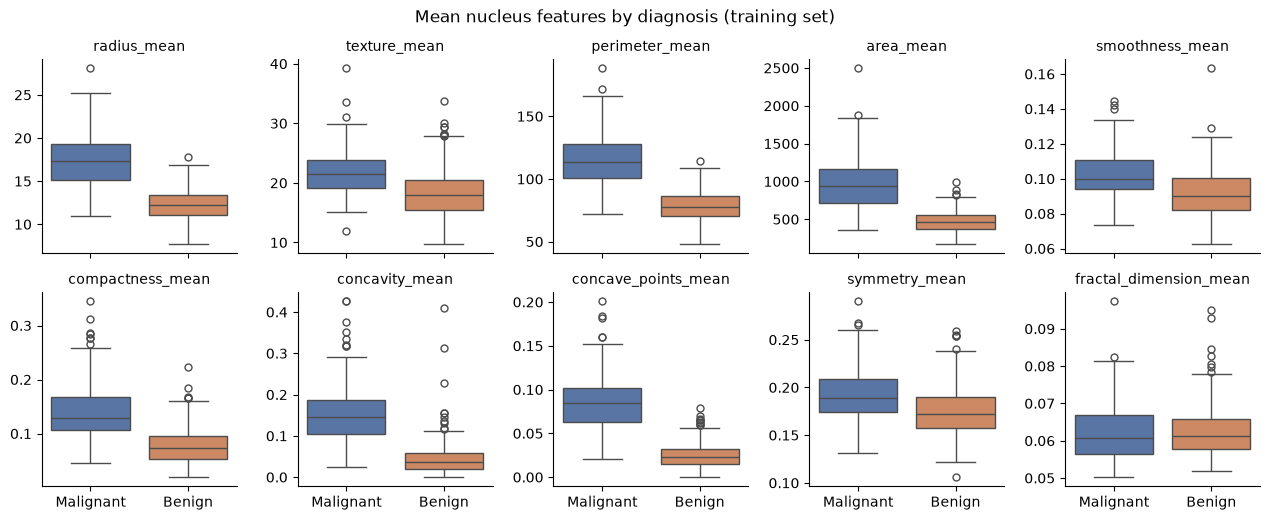

In [4]:
long = X_train.assign(diagnosis=y_train.map({0: "Benign", 1: "Malignant"})).melt(id_vars="diagnosis")
g = sns.catplot(data=long, x="diagnosis", y="value", col="variable", kind="box",
                col_wrap=5, sharey=False, height=2.6, palette=["#4C72B0", "#DD8452"], hue="diagnosis", legend=False)
g.set_titles("{col_name}").set_axis_labels("", "")
g.fig.suptitle("Mean nucleus features by diagnosis (training set)", y=1.03)
g.savefig(FIG_DIR / "feature_boxplots.png", dpi=120, bbox_inches="tight")
plt.show()

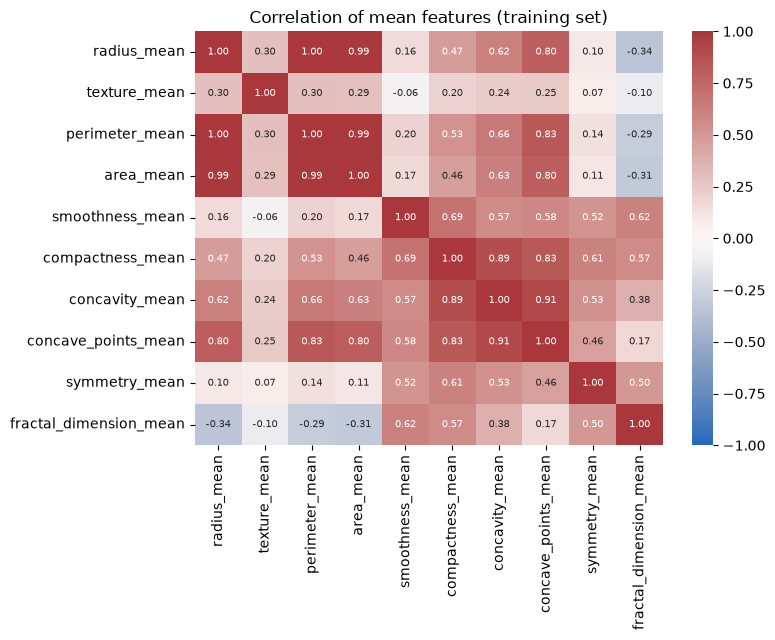

In [5]:
corr = X_train.corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation of mean features (training set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=120)
plt.show()

`radius_mean`, `perimeter_mean` and `area_mean` are almost perfectly correlated (r > 0.99): they measure the same thing (nucleus size). `concavity_mean`, `concave_points_mean` and `compactness_mean` are also strongly related. This matters for the next step.

## Full model on the training set

A logistic regression with all ten standardized mean features. The variance inflation factors (VIF) show severe multicollinearity, so the individual p-values below are unstable: which of the correlated size/shape features looks 'significant' depends largely on the particular sample.

In [6]:
mu, sd = X_train.mean(), X_train.std()
full = sm.Logit(y_train, sm.add_constant((X_train - mu) / sd)).fit(disp=0, maxiter=200)
Z = ((X_train - mu) / sd).values
summary = full.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|"]]
summary["VIF"] = [np.nan] + [variance_inflation_factor(Z, i) for i in range(Z.shape[1])]
summary.round(3)

,Coef.,Std.Err.,P>|z|,VIF
const,0.495,0.630,0.432,NaN
radius_mean,-4.907,16.875,0.771,1598.518
texture_mean,1.998,0.423,0.000,1.175
perimeter_mean,-7.562,16.330,0.643,1939.057
area_mean,16.671,7.172,0.020,65.195
smoothness_mean,1.103,0.596,0.064,3.449
compactness_mean,-0.091,1.366,0.947,25.042
concavity_mean,-0.029,0.867,0.974,10.663
concave_points_mean,4.726,1.647,0.004,22.944
symmetry_mean,0.414,0.358,0.247,1.811


In [7]:
BASE = [f for f in MEAN_FEATURES if full.pvalues[f] < 0.05]
print("Base predictors (p < 0.05 in the full training-set model):", BASE)

Base predictors (p < 0.05 in the full training-set model): ['texture_mean', 'area_mean', 'concave_points_mean']


## Model selection on the validation set

Each candidate adds one remaining feature to the base set. Every model is fit on the **training** set and scored on the **validation** set, which it has not seen. The original texture + concavity + radius model is included for reference.

**Selection rule (fixed before looking at the test set):** lowest validation log loss; models within 0.01 of the best are treated as tied and the one with fewer features wins. Log loss is used because it rewards well-calibrated probabilities, and AUC barely separates the candidates.

In [8]:
def logreg():
    # Unpenalised logistic regression (same model as R's glm), scaled inside the pipeline
    return make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000))

candidates = {"base": BASE}
candidates.update({f"base + {f}": BASE + [f] for f in MEAN_FEATURES if f not in BASE})
candidates["original: texture + concavity + radius"] = ["texture_mean", "concavity_mean", "radius_mean"]

rows = []
for name, feats in candidates.items():
    model = logreg().fit(X_train[feats], y_train)
    p_val = model.predict_proba(X_val[feats])[:, 1]
    aic = sm.Logit(y_train, sm.add_constant(X_train[feats])).fit(disp=0, maxiter=200).aic
    rows.append({"model": name, "n_features": len(feats), "train_AIC": aic,
                 "val_log_loss": log_loss(y_val, p_val), "val_AUC": roc_auc_score(y_val, p_val),
                 "val_accuracy": accuracy_score(y_val, p_val >= 0.5)})
results = pd.DataFrame(rows).set_index("model").sort_values("val_log_loss")
results.round(4)

,n_features,train_AIC,val_log_loss,val_AUC,val_accuracy
model,,,,,
base + smoothness_mean,4,100.3301,0.0998,0.9941,0.9474
base + symmetry_mean,4,102.7205,0.1029,0.9941,0.9561
base + concavity_mean,4,103.9998,0.1066,0.9941,0.9561
base + fractal_dimension_mean,4,104.1655,0.1079,0.9944,0.9561
base,3,102.2022,0.1084,0.9941,0.9561
base + compactness_mean,4,103.0152,0.1096,0.9934,0.9561
base + perimeter_mean,4,99.6289,0.1109,0.9931,0.9561
base + radius_mean,4,101.2490,0.1141,0.9934,0.9561
original: texture + concavity + radius,3,134.0618,0.1520,0.9902,0.9386


In [9]:
eligible = results.drop(index="original: texture + concavity + radius")
tied = eligible[eligible["val_log_loss"] <= eligible["val_log_loss"].min() + 0.01]
chosen = tied.sort_values(["n_features", "val_log_loss"]).index[0]
FEATURES = candidates[chosen]
print("Chosen model:", chosen, "->", FEATURES)

Chosen model: base -> ['texture_mean', 'area_mean', 'concave_points_mean']


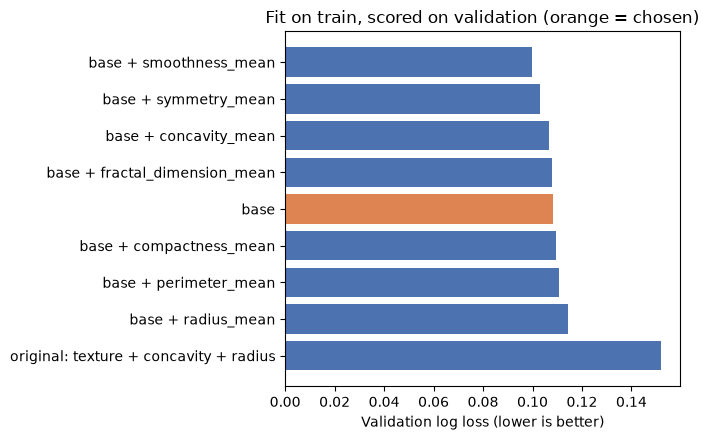

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_df = results["val_log_loss"].sort_values(ascending=False)
colors = ["#DD8452" if m == chosen else "#4C72B0" for m in plot_df.index]
ax.barh(plot_df.index, plot_df.values, color=colors)
ax.set_xlabel("Validation log loss (lower is better)")
ax.set_title("Fit on train, scored on validation (orange = chosen)")
plt.tight_layout()
plt.savefig(FIG_DIR / "model_comparison.png", dpi=120)
plt.show()

## Final model: refit on train + validation, evaluated once on the test set

In [11]:
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])
final = logreg().fit(X_dev[FEATURES], y_dev)

p_test = final.predict_proba(X_test[FEATURES])[:, 1]
pred_test = (p_test >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()

# 95% bootstrap CI for the test AUC (2,000 resamples of the 114 test cases)
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() != yt[idx].max():
        boot.append(roc_auc_score(yt[idx], p_test[idx]))
auc_lo, auc_hi = np.percentile(boot, [2.5, 97.5])

test_metrics = pd.Series({
    "accuracy": (tp + tn) / len(yt),
    "sensitivity (malignant caught)": tp / (tp + fn),
    "specificity (benign cleared)": tn / (tn + fp),
    "AUC": roc_auc_score(yt, p_test),
    "AUC 95% CI low": auc_lo,
    "AUC 95% CI high": auc_hi,
})
print(pd.DataFrame([[tn, fp], [fn, tp]], index=["true benign", "true malignant"],
                   columns=["pred benign", "pred malignant"]))
test_metrics.round(3)

                pred benign  pred malignant
true benign              65               7
true malignant            4              38


accuracy                          0.904
sensitivity (malignant caught)    0.905
specificity (benign cleared)      0.903
AUC                               0.977
AUC 95% CI low                    0.953
AUC 95% CI high                   0.994
dtype: float64

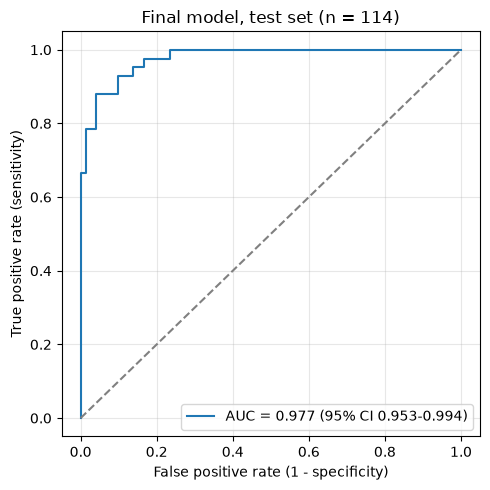

In [12]:
fpr, tpr, _ = roc_curve(yt, p_test)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"AUC = {test_metrics['AUC']:.3f} (95% CI {auc_lo:.3f}-{auc_hi:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False positive rate (1 - specificity)")
plt.ylabel("True positive rate (sensitivity)")
plt.title("Final model, test set (n = 114)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "roc_test.png", dpi=120)
plt.show()

## Interpreting the coefficients

Odds ratios per one standard deviation increase in each feature, from the same final model refit with `statsmodels` (unpenalised, so the estimates match the scikit-learn fit) to get confidence intervals. The intervals are wide because the strongest predictors overlap.

In [13]:
dev_mu, dev_sd = X_dev[FEATURES].mean(), X_dev[FEATURES].std()
sm_final = sm.Logit(y_dev, sm.add_constant((X_dev[FEATURES] - dev_mu) / dev_sd)).fit(disp=0)
odds = np.exp(pd.concat([sm_final.params, sm_final.conf_int()], axis=1))
odds.columns = ["odds ratio per SD", "95% CI low", "95% CI high"]
odds.drop(index="const").round(2)

,odds ratio per SD,95% CI low,95% CI high
texture_mean,4.68,2.58,8.48
area_mean,15.07,4.95,45.90
concave_points_mean,80.38,22.71,284.52


In [14]:
raw = sm.Logit(y_dev, sm.add_constant(X_dev[FEATURES])).fit(disp=0)
equation = "logit(p) = {:.2f} ".format(raw.params["const"]) + " ".join(
    f"{'+' if b >= 0 else '-'} {abs(b):.3g}*{f}" for f, b in raw.params.drop("const").items())
print("Final model on the original feature scale:")
print(equation)

Final model on the original feature scale:
logit(p) = -17.63 + 0.356*texture_mean + 0.00755*area_mean + 111*concave_points_mean


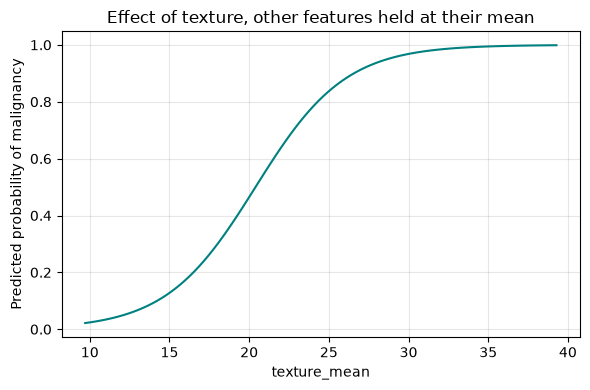

In [15]:
texture_range = np.linspace(X_dev["texture_mean"].min(), X_dev["texture_mean"].max(), 100) \
    if "texture_mean" in FEATURES else None
if texture_range is not None:
    grid = pd.DataFrame({f: X_dev[f].mean() for f in FEATURES}, index=range(100))
    grid["texture_mean"] = texture_range
    plt.figure(figsize=(6, 4))
    plt.plot(texture_range, final.predict_proba(grid[FEATURES])[:, 1], color="teal")
    plt.xlabel("texture_mean")
    plt.ylabel("Predicted probability of malignancy")
    plt.title("Effect of texture, other features held at their mean")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## Limitations

- **Small test set.** 114 cases (42 malignant); one misclassified tumour moves sensitivity by about 2 points. The AUC confidence interval above shows the spread.
- **Feature screening is unstable.** The 'significant' predictors in the full model change with the random split because size and shape features are highly collinear. The R version of this analysis, with a different random split, screens in a different base set (texture and concavity).
- **Threshold 0.5 is arbitrary.** In a diagnostic setting a missed malignancy costs far more than a false alarm, so the threshold should be set for a target sensitivity, using validation data.
- **Only the 10 `_mean` features are used.** The `_se` and `_worst` features (not used here) typically improve accuracy further.
- **Not a clinical tool.** This dataset comes from a single centre in the early 1990s. The model has not been externally validated.